<a href="https://colab.research.google.com/github/mauriciojacomeUPS/Practica1-Mauricio-Jacome/blob/main/Practica1_Mauricio_Jacome.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Practica 01: PREPROCESAMIENTO DE DATOS**

**Asignatura:** Inteligencia Artificial  
**Estudiante:** Mauricio Jácome  

# OBJETIVOS:

- Identificar instancias, atributos, *features* y *labels* en un dataset.
- Clasificar variables según su tipo.
- Aplicar e interpretar las transformaciones Min-Max, Z-Score y Robust Scaler
- Argumentar cuándo y por qué usar cada técnica de escalado según el contexto del dataset
- Probar diferentes librerías y funciones para transformaciones de variables

# ACTIVIDADES A DESARROLLAR:
Abrir un Notebook y ejecutar esta celda de verificación antes de iniciar:

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
import matplotlib.pyplot as plt
print(" Todas las librerías cargadas correctamente")

 Todas las librerías cargadas correctamente


# FASE 1. Anatomía de un Dataset
Dataset de estudiantes. Ejecuta el siguiente bloque. No lo modifiques nada todavía, solo léelo con
atención

In [ ]:
import numpy as np
import pandas as pd
datos = {
 "nombre": ["Ana", "Luis", "María", "Carlos", "Sofía", "Diego"],
 "edad": [21, 23, 20, 25, 22, 21],
 "promedio_gpa": [8.9, 7.4, 9.5, 6.1, 8.2, 7.8],
 "horas_estudio": [18, 10, 22, 6, 15, 12],
 "distancia_km": [2.5, 15.0, 0.8, 40.2, 5.1, 8.7],
 "carrera": [
 "Computación","Computación","Redes","Redes","Computación","Redes"],
 "nivel_ingles": [
 "Básico", "Intermedio","Avanzado","Básico","Avanzado","Intermedio"],
 "beca": [1, 0, 1, 0, 1, 0],"aprobado": ["Sí", "No", "Sí", "No", "Sí", "No"]
}
df = pd.DataFrame(datos)
print(df)
print(f"\nDimensiones del dataset: {df.shape}")
print(df)
print(f"\nDimensiones del dataset: {df.shape}")

   nombre  edad  promedio_gpa  ...  nivel_ingles  beca aprobado
0     Ana    21           8.9  ...        Básico     1       Sí
1    Luis    23           7.4  ...    Intermedio     0       No
2   María    20           9.5  ...      Avanzado     1       Sí
3  Carlos    25           6.1  ...        Básico     0       No
4   Sofía    22           8.2  ...      Avanzado     1       Sí
5   Diego    21           7.8  ...    Intermedio     0       No

[6 rows x 9 columns]

Dimensiones del dataset: (6, 9)
   nombre  edad  promedio_gpa  ...  nivel_ingles  beca aprobado
0     Ana    21           8.9  ...        Básico     1       Sí
1    Luis    23           7.4  ...    Intermedio     0       No
2   María    20           9.5  ...      Avanzado     1       Sí
3  Carlos    25           6.1  ...        Básico     0       No
4   Sofía    22           8.2  ...      Avanzado     1       Sí
5   Diego    21           7.8  ...    Intermedio     0       No

[6 rows x 9 columns]

Dimensiones del dataset: (

# Actividad 1.1: Identifica la estructura. Responde en tu notebook como comentarios o celdas Markdown

P1. ¿Cuántas instancias (filas) tiene este dataset? ¿Qué representa cada instancia en el mundo
real?

*   Tiene 6 instancias que representan a un estudiante con sus datos

P2. Lista todos los atributos (columnas). Ahora sepáralos en dos grupos: ¿cuáles actuarían como
features y cuál sería el label si tu objetivo fuera predecir si un estudiante aprueba o no?

*   Los atributos son nombre, edad, promedio_gpa, horas_estudio, distancia_km, carrera, nivel_ingles, beca y aprobado. Para saber si un estudiante aprueba el label seria aprobado. Las features podrían ser edad, promedio, horas de estudio, distancia, carrera, nivel de inglés y beca

P3. La columna nombre es un atributo, pero ¿debería ser un feature para un modelo de ML? ¿Por
qué sí o por qué no?

*   No. El nombre identifica a la persona, pero en este conjunto no representa una característica que nos ayude para explicar si aprueba o no

# Actividad 1.2: Clasifica las variables. Completa la siguiente tabla en tu notebook. Para cada columna,indica su tipo según los criterios estudiados en clase:

In [ ]:
clasificacion = {
 "columna": ["edad", "promedio_gpa", "horas_estudio", "distancia_km",
 "carrera", "nivel_ingles", "beca", "aprobado"],
 "cuantitativa_o_cualitativa": ["Cuantitativa", "Cuantitativa", "Cuantitativa", "Cuantitativa", "Cualitativa", "Cualitativa", "Cualitativa", "Cualitativa"],
 "discreta_o_continua": ["Discreta", "Continua", "Continua", "Continua", "NA", "NA", "NA", "NA"],
 "nominal_u_ordinal": ["NA", "NA", "NA", "NA", "Nominal", "Ordinal", "Nominal", "Nominal"]
}
df_tipos = pd.DataFrame(clasificacion)
print(df_tipos)

         columna  ... nominal_u_ordinal
0           edad  ...                NA
1   promedio_gpa  ...                NA
2  horas_estudio  ...                NA
3   distancia_km  ...                NA
4        carrera  ...           Nominal
5   nivel_ingles  ...           Ordinal
6           beca  ...           Nominal
7       aprobado  ...           Nominal

[8 rows x 4 columns]


P4. nivel_ingles tiene los valores Básico, Intermedio y Avanzado. ¿Es nominal u ordinal? ¿En
qué te basas para decidirlo? ¿Importa esa distinción a la hora de entrenar un modelo?


*   Es ordinal, porque tiene un orden. Si debe importar a entrenar un modelo porque nos servira para enseñarle a identificar correctamente los niveles de ingles.

P5. La columna beca solo contiene 0 y 1. ¿Es cuantitativa discreta o cualitativa nominal? Justifica
tu respuesta. Pista: piensa en si tiene sentido calcular la media de esos valores.

*   Es nominal porque los 0 y 1 sirven para sabr si un estudiante tiene beca o no

# Actividad 1.3: Inspeccionando tipos de datos

In [ ]:
print("Tipos de datos detectados por pandas:")
print(df.dtypes)
print("\nEstadísticas descriptivas (solo numéricas):")
print(df.describe())

Tipos de datos detectados por pandas:
nombre            object
edad               int64
promedio_gpa     float64
horas_estudio      int64
distancia_km     float64
carrera           object
nivel_ingles      object
beca               int64
aprobado          object
dtype: object

Estadísticas descriptivas (solo numéricas):
            edad  promedio_gpa  horas_estudio  distancia_km      beca
count   6.000000      6.000000       6.000000       6.00000  6.000000
mean   22.000000      7.983333      13.833333      12.05000  0.500000
std     1.788854      1.192337       5.741661      14.68615  0.547723
min    20.000000      6.100000       6.000000       0.80000  0.000000
25%    21.000000      7.500000      10.500000       3.15000  0.000000
50%    21.500000      8.000000      13.500000       6.90000  0.500000
75%    22.750000      8.725000      17.250000      13.42500  1.000000
max    25.000000      9.500000      22.000000      40.20000  1.000000


P6. ¿Coinciden los tipos que detecta pandas (int64, object, float64) con tu clasificación teórica de
la actividad 1.2? Señala al menos un caso donde no coincidan y explica por qué pandas puede
estar "equivocado" desde la perspectiva conceptual.


*   No todos coinciden. Por ejemplo, pandas identifica la columna beca como int64 porque contiene números 0 y 1, pero nosotros la clasificamos como cualitativa nominal porque indica si un estudiante tiene beca o no. Esto pasa porque pandas reconoce el tipo de dato, pero no sabe qué significa realmente.

P7. Observa las estadísticas descriptivas. ¿Qué columna tiene mayor dispersión (std)? ¿Qué
problema podría ocasionar esa diferencia de escala si alimentas este dataset directamente a un
algoritmo como KNN?

*   La columna distancia_km tiene la mayor dispersión, con un std de 14.69 aproximadamente. Esto puede ser un problema para KNN porque trabaja calculando distancias entre los datos, entonces las columnas con valores más grandes podrían influir más que las demás y afectar los resultados

# FASE 2. Escalado con NumPy

En esta fase implementarás los algoritmos desde cero usando solo NumPy. El objetivo es que entiendas
exactamente qué hace cada transformación antes de usar una librería que la oculte.

# Actividad 2.1: Preparando los datos

In [ ]:
# Extraemos SOLO las columnas numéricas continuas para esta fase
columnas_numericas = ["promedio_gpa", "horas_estudio", "distancia_km"]
X = df[columnas_numericas].values.astype(float)
print("Matriz de datos original:")
print(X)
print(f"\nForma: {X.shape} → {X.shape[0]} instancias, {X.shape[1]} features")

Matriz de datos original:
[[ 8.9 18.   2.5]
 [ 7.4 10.  15. ]
 [ 9.5 22.   0.8]
 [ 6.1  6.  40.2]
 [ 8.2 15.   5.1]
 [ 7.8 12.   8.7]]

Forma: (6, 3) → 6 instancias, 3 features


P8. ¿Por qué excluimos edad y beca de esta matriz aunque también son numéricas? ¿Tiene
sentido escalar la columna beca que solo contiene 0 y 1?


*   Excluimos edad porque en este ejercicio se seleccionaron tres columnas, aunque la edad también se podría escalar. En cambio beca solo usa 0 y 1 para saber si un estudiante tiene beca o no. No tiene mucho sentido escalar beca porque sus valores ya están entre 0 y 1.

# Actividad 2.2: Normalización Min-Max

In [ ]:
def min_max_manual(X):
 """
 Normalización Min-Max: transforma cada columna al rango [0, 1]
 Fórmula: x' = (x - min) / (max - min)
 """
 X_min = X.min(axis=0) # mínimo por columna
 X_max = X.max(axis=0) # máximo por columna
 X_norm = (X - X_min) / (X_max - X_min)
 return X_norm, X_min, X_max
X_minmax, mins, maxs = min_max_manual(X)
print("=== RESULTADO MIN-MAX ===")
print(f"{'Feature':<18} {'Min original':>14} {'Max original':>14}")
print("-" * 48)
for i, col in enumerate(columnas_numericas):
 print(f"{col:<18} {mins[i]:>14.2f} {maxs[i]:>14.2f}")
print("\nDatos normalizados (Min-Max):")
df_minmax = pd.DataFrame(X_minmax, columns=[c+"_mm" for c in columnas_numericas])
print(df_minmax.round(4))

=== RESULTADO MIN-MAX ===
Feature              Min original   Max original
------------------------------------------------
promedio_gpa                 6.10           9.50
horas_estudio                6.00          22.00
distancia_km                 0.80          40.20

Datos normalizados (Min-Max):
   promedio_gpa_mm  horas_estudio_mm  distancia_km_mm
0           0.8235            0.7500           0.0431
1           0.3824            0.2500           0.3604
2           1.0000            1.0000           0.0000
3           0.0000            0.0000           1.0000
4           0.6176            0.5625           0.1091
5           0.5000            0.3750           0.2005


P9. Después de aplicar Min-Max, ¿cuál es el valor mínimo y máximo que puede tomar cualquier
columna? Verifica que tus resultados lo confirmen. ¿Qué representa un valor transformado de 0.0?
¿Y uno de 1.0?

*   El valor mínimo es 0 y el máximo es 1, como podemos ver en los resultados. El 0 representa el valor más bajo de la columna y el 1 el más alto.

P10. Fíjate en la columna distancia_km. Carlos vive a 40.2 km, que es un valor extremo. Ahora
imagina que llega un nuevo estudiante que vive a 80 km. Si agregas ese dato y vuelves a
normalizar, ¿qué le pasará al valor transformado de todos los demás estudiantes? ¿Es eso un
problema? ¿Por qué?

*   Los valores de los demás estudiantes disminuirían porque ahora el valor máximo sería 80 km. Esto puede ser un problema porque un solo dato extremo afecta la normalización de los demás y puede hacer que las diferencias entre ellos sean más pequeñas.

# Actividad 2.3: Estandarización Z-Score

In [ ]:
def zscore_manual(X):
 """
 Z-Score: transforma cada columna a media=0 y desv.est.=1
 Fórmula: z = (x - media) / desviacion_estandar
 """
 media = X.mean(axis=0)
 std = X.std(axis=0) # desviación estándar de la población
 X_z = (X - media) / std
 return X_z, media, std
X_zscore, medias, stds = zscore_manual(X)
print("=== RESULTADO Z-SCORE ===")
print(f"{'Feature':<18} {'Media':>10} {'Desv.Est.':>12}")
print("-" * 42)
for i, col in enumerate(columnas_numericas):
 print(f"{col:<18} {medias[i]:>10.3f} {stds[i]:>12.3f}")
print("\nDatos estandarizados (Z-Score):")
df_z = pd.DataFrame(X_zscore, columns=[c+"_z" for c in columnas_numericas])
print(df_z.round(4))

=== RESULTADO Z-SCORE ===
Feature                 Media    Desv.Est.
------------------------------------------
promedio_gpa            7.983        1.088
horas_estudio          13.833        5.241
distancia_km           12.050       13.407

Datos estandarizados (Z-Score):
   promedio_gpa_z  horas_estudio_z  distancia_km_z
0          0.8422           0.7950         -0.7123
1         -0.5359          -0.7314          0.2200
2          1.3934           1.5581         -0.8391
3         -1.7303          -1.4945          2.0997
4          0.1991           0.2226         -0.5184
5         -0.1684          -0.3498         -0.2499


P9. Después de aplicar Min-Max, ¿cuál es el valor mínimo y máximo que puede tomar cualquier
columna? Verifica que tus resultados lo confirmen. ¿Qué representa un valor transformado de 0.0?
¿Y uno de 1.0?


*   El valor mínimo es 0 y el máximo es 1, como podemos ver en los resultados. El 0 representa el valor más bajo de la columna y el 1 el más alto.

P12. Carlos tiene horas_estudio = 6. Después del Z-Score, su valor transformado es negativo.
¿Qué significa eso en términos estadísticos? ¿Significa que Carlos estudia "mal"? ¿Qué dice ese
valor sobre su posición relativa al grupo?

*   Significa que Carlos estudia menos horas que el promedio del grupo. No quiere decir que estudie mal, solo que dedica menos tiempo que los demás estudiantes. Su valor de -1.4945 indica que está por debajo de la media.

P13. Compara los valores de Carlos y Sofía para distancia_km después de Min-Max y después de
Z-Score. ¿Cuál de las dos transformaciones te parece más informativa sobre la "rareza" de vivir a
40 km? Argumenta.

*   Carlos tiene un valor de 1 en Min-Max y 2.0997 en Z-Score, mientras que Sofía tiene valores más bajos. Me parece que Z-Score es más informativo porque nos permite ver qué tan lejos está Carlos del promedio del grupo, mientras que Min-Max solo nos muestra que tiene la distancia más alta.

# Actividad 2.4: Comparación visual de las tres columnas

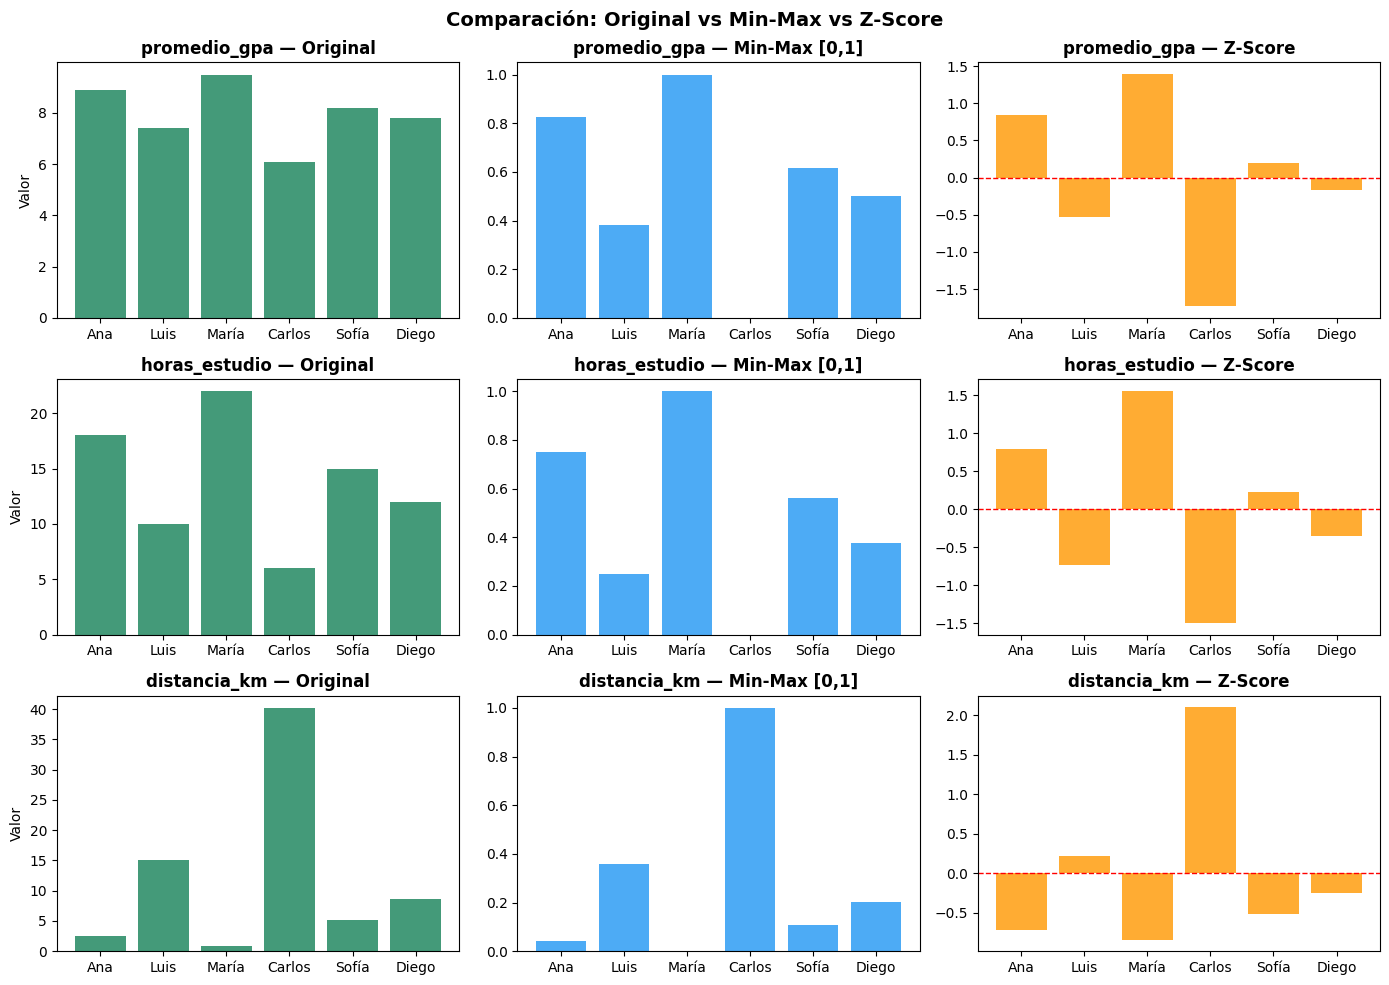

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
nombres = df["nombre"].values
for i, col in enumerate(columnas_numericas):
 # Original
 axes[i, 0].bar(nombres, X[:, i], color="#158158", alpha=0.8)
 axes[i, 0].set_title(f"{col} — Original", fontweight='bold')
 axes[i, 0].set_ylabel("Valor")
# Min-Max
 axes[i, 1].bar(nombres, X_minmax[:, i], color="#2196F3", alpha=0.8)
 axes[i, 1].set_title(f"{col} — Min-Max [0,1]", fontweight='bold')
 # Z-Score
 axes[i, 2].bar(nombres, X_zscore[:, i], color="#FF9800", alpha=0.8)
 axes[i, 2].axhline(0, color='red', linestyle='--', linewidth=1)
 axes[i, 2].set_title(f"{col} — Z-Score", fontweight='bold')
plt.suptitle("Comparación: Original vs Min-Max vs Z-Score", fontsize=14,
fontweight='bold')
plt.tight_layout()
plt.savefig("comparacion_escalado.png", dpi=100)
plt.show()

P14. Observa la gráfica de distancia_km. Las proporciones relativas entre estudiantes, ¿se
mantienen igual en las tres versiones? ¿Qué es lo que realmente cambia entre Original, Min-Max y
Z-Score?


*   No exactamente, el orden de los estudiantes se mantiene, pero los valores cambian. En Original vemos las distancias en kilómetros, con Min-Max los valores están entre 0 y 1, mientras que Z-Score nos muestra qué tan lejos están del promedio. Lo que cambia es la escala de los datos, pero se mantienen las diferencias relativas entre ellos.

# Actividad 2.5: Simulando un outlier extremo

In [ ]:
# Añadimos un estudiante con una distancia extrema
X_con_outlier = np.vstack([X, [8.5, 14, 120.0]]) # 120 km
# Aplicamos Min-Max sobre los datos CON outlier
X_mm_con_outlier, _, _ = min_max_manual(X_con_outlier)
# Aplicamos Z-Score sobre los datos CON outlier
X_z_con_outlier, _, _ = zscore_manual(X_con_outlier)
print("=== Columna distancia_km con outlier (120 km) ===")
print(f"\n{'Estudiante':<10} {'Original':>10} {'Min-Max':>10} {'Z-Score':>10}")
print("-" * 44)
nombres_ext = list(nombres) + ["Nuevo"]
for j in range(len(nombres_ext)):
 print(f"{nombres_ext[j]:<10} {X_con_outlier[j,2]:>10.1f} "
 f"{X_mm_con_outlier[j,2]:>10.4f} {X_z_con_outlier[j,2]:>10.4f}")

=== Columna distancia_km con outlier (120 km) ===

Estudiante   Original    Min-Max    Z-Score
--------------------------------------------
Ana               2.5     0.0143    -0.6280
Luis             15.0     0.1191    -0.3137
María             0.8     0.0000    -0.6708
Carlos           40.2     0.3305     0.3201
Sofía             5.1     0.0361    -0.5626
Diego             8.7     0.0663    -0.4721
Nuevo           120.0     1.0000     2.3271


P15. Observa lo que ocurre con los valores de los otros estudiantes en Min-Max después de
agregar el outlier de 120 km. ¿Qué problema genera esto? ¿Por qué Z-Score es más robusto ante
este caso? ¿Existe alguna técnica mejor aún?

*   El problema es que los valores de los demás estudiantes disminuyen mucho porque ahora el máximo es 120 km. Z-Score nos permite ver qué tan lejos están los valores del promedio, pero también se ve afectado por los valores extremos. Una mejor opción sería RobustScaler porque utiliza la mediana y es menos sensible a estos valores.

# FASE 3. Dataset real con Pandas: Palmer Penguins

Ahora trabajarás con un dataset real de Hugging Face. El dataset Palmer Penguins, creado originalmente
como paquete de R, fue diseñado para reemplazar al famoso Iris dataset en tareas de exploración y
visualización de datos

In [ ]:
import pandas as pd
# Cargamos el dataset directamente desde Hugging Face
url = "https://huggingface.co/datasets/SIH/palmer-penguins/resolve/main/penguins.csv"
df_penguins = pd.read_csv(url)
print("=== PRIMERA VISTA DEL DATASET ===")
print(df_penguins.head(8))
print(f"\nDimensiones: {df_penguins.shape}")
print(f"\nColumnas: {list(df_penguins.columns)}")

=== PRIMERA VISTA DEL DATASET ===
  species     island  bill_length_mm  ...  body_mass_g     sex  year
0  Adelie  Torgersen            39.1  ...       3750.0    male  2007
1  Adelie  Torgersen            39.5  ...       3800.0  female  2007
2  Adelie  Torgersen            40.3  ...       3250.0  female  2007
3  Adelie  Torgersen             NaN  ...          NaN     NaN  2007
4  Adelie  Torgersen            36.7  ...       3450.0  female  2007
5  Adelie  Torgersen            39.3  ...       3650.0    male  2007
6  Adelie  Torgersen            38.9  ...       3625.0  female  2007
7  Adelie  Torgersen            39.2  ...       4675.0    male  2007

[8 rows x 8 columns]

Dimensiones: (344, 8)

Columnas: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'year']


# Actividad 3.1: Exploración inicial obligatoria

In [ ]:
print("\n=== TIPOS DE DATOS ===")
print(df_penguins.dtypes)
print("\n=== VALORES NULOS ===")
print(df_penguins.isnull().sum())
print("\n=== ESTADÍSTICAS DESCRIPTIVAS ===")
print(df_penguins.describe())
print("\n=== VALORES ÚNICOS EN COLUMNAS CATEGÓRICAS ===")
for col in df_penguins.select_dtypes(include='object').columns:
 print(f"{col}: {df_penguins[col].unique()}")


=== TIPOS DE DATOS ===
species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
year                   int64
dtype: object

=== VALORES NULOS ===
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

=== ESTADÍSTICAS DESCRIPTIVAS ===
       bill_length_mm  bill_depth_mm  ...  body_mass_g         year
count      342.000000     342.000000  ...   342.000000   344.000000
mean        43.921930      17.151170  ...  4201.754386  2008.029070
std          5.459584       1.974793  ...   801.954536     0.818356
min         32.100000      13.100000  ...  2700.000000  2007.000000
25%         39.225000      15.600000  ...  3550.000000  2007.000000
50%         44.450000      17.300000  ...  4050.000000  200

P16. Identifica para este dataset: ¿cuántas instancias tiene? ¿Cuáles son las features numéricas?
¿Cuál sería el label más lógico para una tarea de clasificación?


*   El dataset tiene 344 instancias que representan a los pingüinos. Las features numéricas son bill_length_mm, bill_depth_mm, flipper_length_mm, body_mass_g y year. El label más lógico sería species porque queremos identificar a qué especie pertenece cada pingüino.

P17. ¿Hay valores nulos? ¿En qué columnas? ¿Por qué es importante tratar los valores nulos
antes de aplicar escalado? ¿Qué pasaría si escalas con NaN presentes?

*   Sí hay valores nulos, tenemos 2 en bill_length_mm, bill_depth_mm, flipper_length_mm y body_mass_g, además de 11 en sex. Es importante tratarlos antes de escalar porque son datos que faltan y pueden afectar los resultados. Si escalamos con NaN, algunos valores seguirían siendo NaN y podrían causar problemas al entrenar el modelo.

# Actividad 3.2: Clasificación de variables del dataset

P18. Para cada columna de df_penguins, clasifica su tipo completo. Presta especial atención a sex
e island. ¿Son las dos nominales? ¿Cambiaría la respuesta si ordenamos las islas por temperatura
promedio del océano?

* Las columnas species, island y sex son cualitativas nominales porque representan categorías sin un orden. Las columnas bill_length_mm, bill_depth_mm, flipper_length_mm y body_mass_g son cuantitativas continuas porque son medidas físicas. La columna year es cuantitativa discreta porque representa años enteros.

* Sí, sex e island son nominales porque no tienen un orden. Si ordenamos las islas por la temperatura promedio del océano, podríamos usar ese orden para compararlas, pero island seguiría siendo nominal porque solo representa el nombre de la isla.

# Actividad 3.3: Preprocesamiento y escalado

In [ ]:
# Paso 1: Eliminar filas con valores nulos
df_clean = df_penguins.dropna()
print(f"Filas originales: {len(df_penguins)} → Filas limpias: {len(df_clean)}")
# Paso 2: Seleccionar features numéricas
features_num = ["bill_length_mm", "bill_depth_mm",
 "flipper_length_mm", "body_mass_g"]
X_penguins = df_clean[features_num].values
print("\nEstadísticas ANTES del escalado:")
print(pd.DataFrame(X_penguins, columns=features_num).describe().round(2))

Filas originales: 344 → Filas limpias: 333

Estadísticas ANTES del escalado:
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count          333.00         333.00             333.00       333.00
mean            43.99          17.16             200.97      4207.06
std              5.47           1.97              14.02       805.22
min             32.10          13.10             172.00      2700.00
25%             39.50          15.60             190.00      3550.00
50%             44.50          17.30             197.00      4050.00
75%             48.60          18.70             213.00      4775.00
max             59.60          21.50             231.00      6300.00


P19. Mira las escalas de body_mass_g (en gramos, ~3500–6000) vs bill_depth_mm (en mm,
~13–21). Si entrenas un modelo con estos datos sin escalar, ¿cuál variable tendrá más peso en el cálculo de distancia? ¿Es eso justo biológicamente?

*   body_mass_g podría dominar porque sus valores están alrededor de miles de gramos, mientras que las otras medidas usan números mucho menores. Esto no significa que el peso sea más importante biológicamente; solo significa que tiene una escala numérica mayor.

# Actividad 3.4: Análisis de distribuciones

In [ ]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Paso 3: Aplicar Min-Max
mm = MinMaxScaler()
X_mm = mm.fit_transform(X_penguins)

# Paso 4: Aplicar Z-Score
zs = StandardScaler()
X_zs = zs.fit_transform(X_penguins)

# Paso 5: Comparar estadísticas
print("\n--- Min-Max ---")
print(pd.DataFrame(X_mm, columns=features_num).describe().round(4))
print("\n--- Z-Score ---")
print(pd.DataFrame(X_zs, columns=features_num).describe().round(4))


--- Min-Max ---
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count        333.0000       333.0000           333.0000     333.0000
mean           0.4325         0.4839             0.4910       0.4186
std            0.1989         0.2344             0.2376       0.2237
min            0.0000         0.0000             0.0000       0.0000
25%            0.2691         0.2976             0.3051       0.2361
50%            0.4509         0.5000             0.4237       0.3750
75%            0.6000         0.6667             0.6949       0.5764
max            1.0000         1.0000             1.0000       1.0000

--- Z-Score ---
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count        333.0000       333.0000           333.0000     333.0000
mean          -0.0000        -0.0000             0.0000      -0.0000
std            1.0015         1.0015             1.0015       1.0015
min           -2.1780        -2.0673            -2.0699      -1.8744


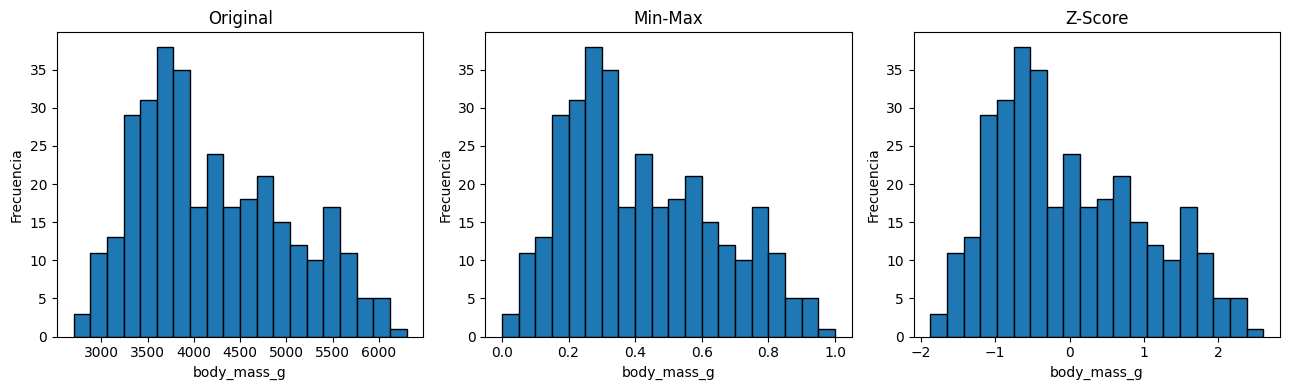

In [ ]:
# Comparar la distribución de body_mass_g
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
datos = [X_penguins[:, 3], X_mm[:, 3], X_zs[:, 3]]
titulos = ["Original", "Min-Max", "Z-Score"]
for i in range(3):
    axes[i].hist(datos[i], bins=20, edgecolor="black")
    axes[i].set_title(titulos[i])
    axes[i].set_xlabel("body_mass_g")
    axes[i].set_ylabel("Frecuencia")
plt.tight_layout()
plt.show()

P20. ¿El escalado cambia la forma de la distribución (histograma) o solo la escala de los ejes?
¿Por qué importa esa respuesta cuando evaluamos normalidad de los datos?


*  El escalado solo cambia los valores de los ejes, pero la forma del histograma se mantiene igual. Por ejemplo, si los datos tienen una distribución asimétrica, seguirán así después de aplicar Min-Max o Z-Score. Esto es importante porque escalar los datos no significa que se vuelvan normales, simplemente estamos cambiando sus valores para poder compararlos mejor.

P21. Observa la distribución de body_mass_g. ¿Se parece a una campana de Gauss (distribución
normal) o tiene alguna asimetría? ¿Afecta eso a la elección entre Min-Max y Z-Score?


*   La distribución de body_mass_g no tiene exactamente la forma de una campana de Gauss. Se puede observar cierta asimetría hacia la derecha, porque hay pingüinos que pesan más que otros. Esto sí puede influir al momento de elegir el método de escalado, ya que Min-Max depende de los valores mínimos y máximos, mientras que Z-Score utiliza la media y la desviación estándar. Los dos métodos pueden utilizarse, pero hay que tener en cuenta que ninguno elimina la asimetría de los datos.

# FASE 4: HuggingFace + sklearn

En la fase anterior implementaste Min-Max y Z-Score desde cero con NumPy. Ahora vas a reproducir
exactamente los mismos resultados usando sklearn, y añadirás un tercer método que no puedes
implementar tan fácilmente a mano: el Robust Scaler. El dataset sigue siendo Palmer Penguins, que ya
conoces.

# Actividad 4.1: Retornando al dataset limpio

Asegúrate de tener el DataFrame df_clean y las columnas features_num de la Fase 3. Si reiniciaste
el kernel, ejecuta esto:

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
url = "https://huggingface.co/datasets/SIH/palmer-penguins/resolve/main/penguins.csv"
df_penguins = pd.read_csv(url)
df_clean = df_penguins.dropna()
features_num = ["bill_length_mm", "bill_depth_mm",
 "flipper_length_mm", "body_mass_g"]
X = df_clean[features_num].values
print(f"Dataset listo: {X.shape[0]} instancias, {X.shape[1]} features")
print(f"\nEstadísticas originales:")
print(pd.DataFrame(X, columns=features_num).describe().round(2))

Dataset listo: 333 instancias, 4 features

Estadísticas originales:
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count          333.00         333.00             333.00       333.00
mean            43.99          17.16             200.97      4207.06
std              5.47           1.97              14.02       805.22
min             32.10          13.10             172.00      2700.00
25%             39.50          15.60             190.00      3550.00
50%             44.50          17.30             197.00      4050.00
75%             48.60          18.70             213.00      4775.00
max             59.60          21.50             231.00      6300.00


In [ ]:
# Calcular el rango de cada feature
rangos = df_clean[features_num].max() - df_clean[features_num].min()

print("Rangos de las features:")
print(rangos)

print("\nMayor rango:", rangos.idxmax(), "=", rangos.max())
print("Menor rango:", rangos.idxmin(), "=", rangos.min())

Rangos de las features:
bill_length_mm         27.5
bill_depth_mm           8.4
flipper_length_mm      59.0
body_mass_g          3600.0
dtype: float64

Mayor rango: body_mass_g = 3600.0
Menor rango: bill_depth_mm = 8.4


P22. Antes de continuar: ¿cuál de las cuatro features tiene mayor rango (max − min)? ¿Cuál tiene
menor rango? Calcula ambos valores con código y anótalos, los vas a necesitar para comparar
después

*   La feature con mayor rango es body_mass_g, con un valor de 3600 g (6300 - 2700). La que tiene menor rango es bill_depth_mm, con 8.4 mm (21.5 - 13.1). Esto nos muestra que las variables tienen escalas bastante diferentes, por lo que es importante aplicar el escalado para que ninguna tenga más influencia solo por sus valores numéricos.

# Actividad 4.2: División train/test. Antes de escalar, el dataset debe dividirse. Este orden no es opcional

In [ ]:
X_train, X_test = train_test_split(
    X,
    test_size=0.2,   # 80% entrenamiento y 20% prueba
    random_state=42  # para repetir el resultado
)
print(f"Train: {X_train.shape} → {X_train.shape[0]} pingüinos")
print(f"Test:  {X_test.shape} → {X_test.shape[0]} pingüinos")

Train: (266, 4) → 266 pingüinos
Test:  (67, 4) → 67 pingüinos


P23. ¿Por qué se divide el dataset antes de aplicar el escalado y no después? Piensa en qué
información usaría el scaler si lo aplicaras primero sobre todo el dataset. ¿Qué datos del test
estarías "filtrando" al proceso de entrenamiento? Esto se llama data leakage; explícalo con tus
propias palabras.

*   Se divide el dataset antes de escalar para evitar que los datos de prueba influyan en el entrenamiento. Si escalamos primero, estaríamos usando información del test que el modelo no debería conocer. Esto se llama data leakage y puede hacer que los resultados no sean tan confiables.

# Actividad 4.3: Aplicando los tres escaladores El patrón de uso es siempre el mismo:

*   fit_transform(X_train) → aprende los parámetros del train y lo transforma
*   transform(X_test) → aplica los mismos parámetros aprendidos al test, sin recalcularlos

In [ ]:
# Instanciar los tres escaladores
mm_scaler = MinMaxScaler()
zs_scaler = StandardScaler()
rb_scaler = RobustScaler()
# Aplicar a train: fit + transform
X_train_mm = mm_scaler.fit_transform(X_train)
X_train_zs = zs_scaler.fit_transform(X_train)
X_train_rb = rb_scaler.fit_transform(X_train)
# Aplicar a test: solo transform (NO fit)
X_test_mm = mm_scaler.transform(X_test)
X_test_zs = zs_scaler.transform(X_test)
X_test_rb = rb_scaler.transform(X_test)
print("Parámetros aprendidos por MinMaxScaler (sobre train):")
print(f" Mínimos: {mm_scaler.data_min_.round(2)}")
print(f" Máximos: {mm_scaler.data_max_.round(2)}")
print("\nParámetros aprendidos por StandardScaler (sobre train):")
print(f" Medias: {zs_scaler.mean_.round(2)}")
print(f" Std: {zs_scaler.scale_.round(2)}")
print("\nParámetros aprendidos por RobustScaler (sobre train):")
print(f" Medianas: {rb_scaler.center_.round(2)}")
print(f" IQR: {rb_scaler.scale_.round(2)}")

Parámetros aprendidos por MinMaxScaler (sobre train):
 Mínimos: [  32.1   13.1  172.  2700. ]
 Máximos: [  59.6   21.5  231.  6050. ]

Parámetros aprendidos por StandardScaler (sobre train):
 Medias: [  44.08   17.07  201.41 4232.61]
 Std: [  5.41   1.97  14.24 809.57]

Parámetros aprendidos por RobustScaler (sobre train):
 Medianas: [  44.9   17.2  197.  4100. ]
 IQR: [   8.9    3.2   24.  1200. ]


P22. Compara los parámetros que aprendió MinMaxScaler (mínimos y máximos) con los que
calculaste manualmente en la Fase 2 con NumPy. ¿Son exactamente iguales o hay alguna
diferencia pequeña? ¿A qué se debe si la hay?

*   Casi todos los valores son iguales, pero hay una diferencia en body_mass_g. Antes el máximo era 6300 g y ahora es 6050 g. Esto pasa porque el escalador solo utiliza el 80% de los datos para entrenar, por lo que algunos valores pueden quedar fuera.

P23. El RobustScaler aprende la mediana y el IQR de cada columna, no la media ni el std. Calcula
manualmente la mediana y el IQR de body_mass_g en el train con NumPy y verifica que
coincidan con rb_scaler.center_[3] y rb_scaler.scale_[3].

*   Al calcular la mediana y el IQR con NumPy obtuve 4100 y 1200. Al compararlos con los valores de RobustScaler, podemos ver que coinciden, por lo que el escalador realizó correctamente los cálculos.

In [ ]:
from sklearn.preprocessing import RobustScaler

# Crear y entrenar RobustScaler
rb_scaler = RobustScaler()
rb_scaler.fit(X_train)

# Calcular mediana e IQR de body_mass_g
peso = X_train[:, 3]

mediana = np.median(peso)
iqr = np.percentile(peso, 75) - np.percentile(peso, 25)

print("Mediana:", mediana)
print("IQR:", iqr)

# Comparar con RobustScaler
print("Mediana RobustScaler:", rb_scaler.center_[3])
print("IQR RobustScaler:", rb_scaler.scale_[3])

Mediana: 4100.0
IQR: 1200.0
Mediana RobustScaler: 4100.0
IQR RobustScaler: 1200.0


### Conclusión

En esta práctica pude comprender mejor la importancia de revisar y conocer los datos antes de utilizarlos, ya que algunas variables pueden representar categorías aunque estén expresadas con números. También aprendí las diferencias entre Min-Max y Z-Score, y cómo los valores extremos pueden influir en sus resultados. Al trabajar con el dataset Palmer Penguins, entendí por qué es necesario revisar los datos faltantes y separar los datos de entrenamiento y prueba antes de aplicar el escalado. Finalmente, comprendí que no existe un método de escalado que sea mejor en todos los casos, sino que su elección depende del tipo de datos y del algoritmo que se vaya a utilizar.